In [16]:
# Setup: imports and reproducibility
import numpy as np
import torch
import torch.nn as nn
import random
import matplotlib.pyplot as plt

random.seed(0)
torch.manual_seed(0)

WHITE, BLACK = 1, -1

In [17]:
def init_board():
    board = np.zeros(24, dtype=int)
    board[23], board[12], board[7], board[5] = 2, 5, 3, 5        # White checkers
    board[0], board[11], board[16], board[18] = -2, -5, -3, -5   # Black checkers
    bar = {WHITE: 0, BLACK: 0}
    off = {WHITE: 0, BLACK: 0}
    return board, bar, off

In [18]:
def home_points(player):
    return range(0, 6) if player == WHITE else range(18, 24)

def can_bear_off(board, player):
    home = set(home_points(player))
    return not any(board[p] * player > 0 and p not in home for p in range(24))

def bear_off_ok(board, player, frm, die):
    if not can_bear_off(board, player):
        return False
    dist = (frm + 1) if player == WHITE else (24 - frm)
    if die == dist:
        return True
    if die > dist:  # overshoot allowed only if no checkers further from home
        farther = range(frm + 1, 6) if player == WHITE else range(18, frm)
        return not any(board[p] * player > 0 for p in farther)
    return False

def point_open(board, player, to):
    return board[to] * player >= 0 or abs(board[to]) == 1  # empty, own, or a hittable blot

In [19]:
def apply_single_move(board, bar, off, player, frm, die):
    board, bar, off = board.copy(), dict(bar), dict(off)
    direction = -player  # White moves 23 -> 0, Black moves 0 -> 23

    if frm == -1:  # entering from the bar
        to = 24 - die if player == WHITE else die - 1
        if bar[player] == 0 or not point_open(board, player, to):
            return None
        bar[player] -= 1
    else:
        if board[frm] * player <= 0:
            return None
        to = frm + direction * die
        if to < 0 or to > 23:  # bearing off
            if not bear_off_ok(board, player, frm, die):
                return None
            board[frm] -= player
            off[player] += 1
            return board, bar, off
        if not point_open(board, player, to):
            return None
        board[frm] -= player

    if abs(board[to]) == 1 and board[to] * player < 0:  # hit a blot
        board[to] = 0
        bar[-player] += 1
    board[to] += player
    return board, bar, off

In [20]:
def board_key(board, bar, off):
    return (tuple(board.tolist()), bar[WHITE], bar[BLACK], off[WHITE], off[BLACK])

def generate_turn_states(board, bar, off, player, dice):
    states = {board_key(board, bar, off): (board, bar, off, 0)}
    for die in dice:
        next_states = {}
        for b, ba, o, used in states.values():
            moved = False
            sources = [-1] if ba[player] > 0 else [p for p in range(24) if b[p] * player > 0]
            for frm in sources:
                new = apply_single_move(b, ba, o, player, frm, die)
                if new:
                    moved = True
                    k = board_key(*new)
                    if k not in next_states or next_states[k][3] < used + 1:
                        next_states[k] = (*new, used + 1)
            if not moved:  # this die can't be used from this state
                k = board_key(b, ba, o)
                if k not in next_states or next_states[k][3] < used:
                    next_states[k] = (b, ba, o, used)
        states = next_states
    max_used = max(s[3] for s in states.values())
    return [(b, ba, o) for b, ba, o, u in states.values() if u == max_used]

def generate_full_turn(board, bar, off, player, d1, d2):
    dice_orders = [[d1] * 4] if d1 == d2 else [[d1, d2], [d2, d1]]
    found = {}
    for dice in dice_orders:
        for s in generate_turn_states(board, bar, off, player, dice):
            found[board_key(*s)] = s
    return list(found.values())

## Neural network
Board encoding + the value network. Like the referenced TD-Gammon project, the network
takes an encoded board as input and outputs a single number: the estimated probability
that White eventually wins from this position.

In [21]:
# Tesauro-style board encoding: 4 units per point per color, plus bar, off, and
# whose-turn-it-is units. 24 points x 2 colors x 4 units + 2 + 2 + 2 = 198 inputs.

def encode_point(n):
    return [1.0 if n >= 1 else 0.0, 1.0 if n >= 2 else 0.0,
            1.0 if n >= 3 else 0.0, max(n - 3, 0) / 2.0]

def encode_board(board, bar, off, player):
    feats = []
    for p in range(24):
        feats += encode_point(board[p] if board[p] > 0 else 0)
        feats += encode_point(-board[p] if board[p] < 0 else 0)
    feats += [bar[WHITE] / 2.0, bar[BLACK] / 2.0]
    feats += [off[WHITE] / 15.0, off[BLACK] / 15.0]
    feats += [1.0, 0.0] if player == WHITE else [0.0, 1.0]
    return np.array(feats, dtype=np.float32)

In [22]:
# The value network: one hidden layer, sigmoid output = P(White wins)

class TDGammonNet(nn.Module):
    def __init__(self, hidden_units=40):
        super().__init__()
        self.fc1 = nn.Linear(198, hidden_units)
        self.fc2 = nn.Linear(hidden_units, 1)

    def forward(self, x):
        h = torch.sigmoid(self.fc1(x))
        return torch.sigmoid(self.fc2(h))

In [23]:
# Evaluate a position: probability White eventually wins from here

def evaluate(net, board, bar, off, player):
    x = torch.from_numpy(encode_board(board, bar, off, player))
    with torch.no_grad():
        return net(x).item()

## Move selection: 1-ply vs 2-ply
- **1-ply** = the agent's move only. Evaluate every legal resulting board and pick the
  best one directly.
- **2-ply** = the agent's move + the opponent's best reply. For each candidate move,
  average the opponent's best 1-ply response over all 21 possible dice rolls, weighted
  by their probability, then pick the candidate that looks best after that reply.

In [24]:
# 1-ply move selection: White maximizes P(White wins), Black minimizes it

def select_1ply(net, board, bar, off, player, d1, d2):
    candidates = generate_full_turn(board, bar, off, player, d1, d2)
    opponent = -player
    values = [evaluate(net, b, ba, o, opponent) for b, ba, o in candidates]
    best = np.argmax(values) if player == WHITE else np.argmin(values)
    return candidates[best]

In [25]:
# 2-ply move selection: look one move further, past the opponent's best reply

DICE_ROLLS = [(a, b) for a in range(1, 7) for b in range(1, 7) if a <= b]
def roll_weight(a, b):
    return 1 if a == b else 2

def select_2ply(net, board, bar, off, player, d1, d2):
    candidates = generate_full_turn(board, bar, off, player, d1, d2)
    opponent = -player
    best, best_val = None, None
    for b, ba, o in candidates:
        if o[player] == 15:
            val = 1.0 if player == WHITE else 0.0
        else:
            total = 0.0
            for r1, r2 in DICE_ROLLS:
                opp_moves = generate_full_turn(b, ba, o, opponent, r1, r2)
                opp_vals = [evaluate(net, cb, cba, co, player) for cb, cba, co in opp_moves]
                reply = max(opp_vals) if opponent == WHITE else min(opp_vals)
                total += roll_weight(r1, r2) * reply
            val = total / 36
        if best_val is None or (player == WHITE and val > best_val) or (player == BLACK and val < best_val):
            best_val, best = val, (b, ba, o)
    return best

## Training (`train.py` equivalent)
The TD(&lambda;) update rule with eligibility traces, and the self-play training loop.
Training uses 1-ply search to pick moves (fast); 2-ply is used only at move-selection
time for the comparison at the end.

In [26]:
def td_update(net, traces, state_vec, target, alpha, lam):
    net.zero_grad()
    value = net(state_vec)
    value.backward()
    with torch.no_grad():
        error = target - value.item()
        for p, trace in zip(net.parameters(), traces):
            trace.mul_(lam).add_(p.grad)
            p.add_(alpha * error * trace)
    return error

In [27]:
def random_move(board, bar, off, player, d1, d2):
    return random.choice(generate_full_turn(board, bar, off, player, d1, d2))

def eval_vs_random(net, games=20):
    wins = 0
    for _ in range(games):
        board, bar, off = init_board()
        player = WHITE
        for _ in range(500):
            d1, d2 = random.randint(1, 6), random.randint(1, 6)
            if player == WHITE:
                board, bar, off = select_1ply(net, board, bar, off, player, d1, d2)
            else:
                board, bar, off = random_move(board, bar, off, player, d1, d2)
            if off[WHITE] == 15:
                wins += 1; break
            if off[BLACK] == 15:
                break
            player = -player
    return wins / games

In [28]:
# Self-play training loop: play a full game, TD-update the network after every ply

def train(hidden_units=40, alpha=0.1, lam=0.7, episodes=200, eval_every=50, eval_games=20, seed=0):
    torch.manual_seed(seed); random.seed(seed)
    net = TDGammonNet(hidden_units)
    history = []

    for ep in range(1, episodes + 1):
        board, bar, off = init_board()
        player = WHITE
        traces = [torch.zeros_like(p) for p in net.parameters()]
        state_vec = torch.from_numpy(encode_board(board, bar, off, player))

        for _ in range(500):  # safety cap on turns per game
            d1, d2 = random.randint(1, 6), random.randint(1, 6)
            board, bar, off = select_1ply(net, board, bar, off, player, d1, d2)

            if off[player] == 15:  # game over
                reward = 1.0 if player == WHITE else 0.0
                td_update(net, traces, state_vec, reward, alpha, lam)
                break

            player = -player
            next_vec = torch.from_numpy(encode_board(board, bar, off, player))
            with torch.no_grad():
                next_val = net(next_vec).item()
            td_update(net, traces, state_vec, next_val, alpha, lam)
            state_vec = next_vec

        if ep % eval_every == 0:
            wr = eval_vs_random(net, games=eval_games)
            history.append((ep, wr))
            print(f"episode {ep:4d}  win rate vs random: {wr:.2f}")

    return net, history

## Baseline training run

episode   50  win rate vs random: 0.80
episode  100  win rate vs random: 0.75
episode  150  win rate vs random: 0.60
episode  200  win rate vs random: 0.55
episode  250  win rate vs random: 0.85
episode  300  win rate vs random: 0.75
episode  350  win rate vs random: 0.35
episode  400  win rate vs random: 0.65
episode  450  win rate vs random: 0.75
episode  500  win rate vs random: 0.55
episode  550  win rate vs random: 0.85
episode  600  win rate vs random: 0.65
episode  650  win rate vs random: 0.40
episode  700  win rate vs random: 0.45
episode  750  win rate vs random: 0.40
episode  800  win rate vs random: 0.60
episode  850  win rate vs random: 0.25
episode  900  win rate vs random: 0.60
episode  950  win rate vs random: 0.45
episode 1000  win rate vs random: 0.75


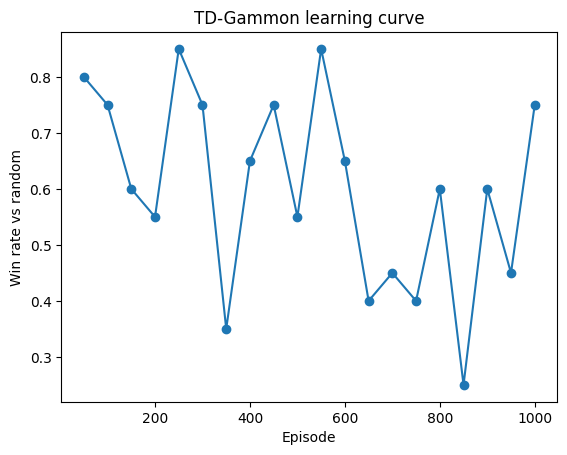

In [29]:
baseline_net, baseline_history = train(hidden_units=40, alpha=0.1, lam=0.7,
                                        episodes=1000, eval_every=50, eval_games=20)

eps, wrs = zip(*baseline_history)
plt.plot(eps, wrs, marker='o')
plt.xlabel("Episode"); plt.ylabel("Win rate vs random")
plt.title("TD-Gammon learning curve"); plt.show()

## Hyperparameter experiment
Compares learning rate (`alpha`), eligibility-trace decay (`lambda`), and hidden-layer
size. Every config starts from the same seed, so differences in the curves come from
the hyperparameters, not from luck in initialization or dice rolls.

In [32]:
configs = [
    {"hidden_units": 40, "alpha": 0.1,  "lam": 0.7},  # baseline
    {"hidden_units": 40, "alpha": 0.01, "lam": 0.7},  # slower learning rate
    {"hidden_units": 40, "alpha": 0.1,  "lam": 0.0},  # no eligibility trace (pure TD(0))
    {"hidden_units": 80, "alpha": 0.1,  "lam": 0.7},  # bigger network
]

sweep_results = {}
for cfg in configs:
    label = f"h={cfg['hidden_units']} a={cfg['alpha']} lam={cfg['lam']}"
    _, hist = train(episodes=500, eval_every=100, eval_games=10, **cfg)
    sweep_results[label] = hist

episode  100  win rate vs random: 0.60
episode  200  win rate vs random: 0.90
episode  300  win rate vs random: 0.70
episode  400  win rate vs random: 0.60
episode  500  win rate vs random: 0.30
episode  100  win rate vs random: 0.20
episode  200  win rate vs random: 0.50
episode  300  win rate vs random: 0.50
episode  400  win rate vs random: 0.40
episode  500  win rate vs random: 0.60
episode  100  win rate vs random: 0.30
episode  200  win rate vs random: 0.60
episode  300  win rate vs random: 0.50
episode  400  win rate vs random: 0.60
episode  500  win rate vs random: 0.60
episode  100  win rate vs random: 0.50
episode  200  win rate vs random: 0.50
episode  300  win rate vs random: 0.50
episode  400  win rate vs random: 0.60
episode  500  win rate vs random: 0.40


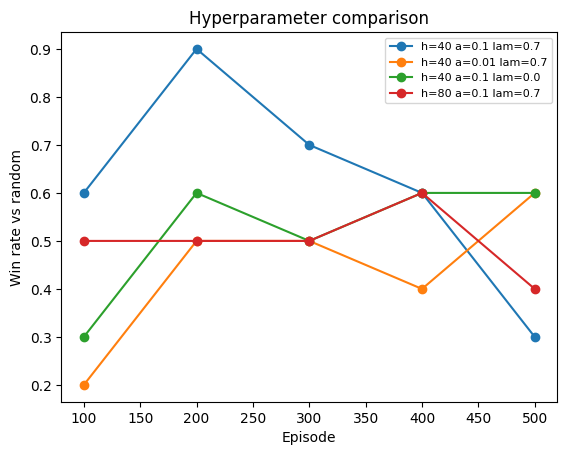

In [33]:
# Plot: effect of hyperparameters on learning speed
for label, hist in sweep_results.items():
    eps, wrs = zip(*hist)
    plt.plot(eps, wrs, marker='o', label=label)
plt.xlabel("Episode"); plt.ylabel("Win rate vs random")
plt.legend(fontsize=8); plt.title("Hyperparameter comparison"); plt.show()

## Comparing 1-ply vs 2-ply search
Same trained network, different search depth at move-selection time. 2-ply accounts
for the opponent's best reply (averaged over all their dice rolls), so it should tend
toward safer moves that leave fewer blots exposed — at a much higher computational
cost per move (roughly 21x more positions evaluated per candidate).

In [34]:
# Head-to-head match: White uses 2-ply, Black uses 1-ply (same network for both)

def play_match(net, white_ply, black_ply, games=5):
    wins = 0
    for _ in range(games):
        board, bar, off = init_board()
        player = WHITE
        for _ in range(500):
            d1, d2 = random.randint(1, 6), random.randint(1, 6)
            ply = white_ply if player == WHITE else black_ply
            select = select_1ply if ply == 1 else select_2ply
            board, bar, off = select(net, board, bar, off, player, d1, d2)
            if off[WHITE] == 15:
                wins += 1; break
            if off[BLACK] == 15:
                break
            player = -player
    return wins / games

wr = play_match(baseline_net, white_ply=2, black_ply=1, games=5)
print(f"White (2-ply) vs Black (1-ply) win rate: {wr:.2f}")

White (2-ply) vs Black (1-ply) win rate: 0.40


In [35]:
random.seed(7)
board, bar, off = init_board()
player = WHITE
agree, total = 0, 10
for _ in range(total):
    d1, d2 = random.randint(1, 6), random.randint(1, 6)
    m1 = select_1ply(baseline_net, board, bar, off, player, d1, d2)
    m2 = select_2ply(baseline_net, board, bar, off, player, d1, d2)
    agree += board_key(*m1) == board_key(*m2)
    board, bar, off = m1  # advance the game using the 1-ply move
    player = -player
    if off[WHITE] == 15 or off[BLACK] == 15:
        break

print(f"1-ply and 2-ply agreed on {agree}/{total} decisions")

1-ply and 2-ply agreed on 6/10 decisions
